Research questions:
- Can cosine similarity between feature maps serve as an empirical proxy for representational overlap?
- How do standard and inverted bottlenecks differ in their channel-level representations?
- Since Elhage et al.'s psi measure is difficult to apply to real CNNs, can complementary measures such as effective rank or sparse autoencoders provide stronger evidence?


Imports (Libraries & dataset)

In [1]:
import torch
import torch.nn as nn

from architecture import BaselineConvNet, StandardConvNetBN, InvertedConvNetBN
from train import train, model_evaluation, plot_cfm, plot_training_dyn, print_per_class_metrics
from utils import get_cifar_subset, cifar10_classes

#selecting a subset of the 10 CIFAR-10 classes bc the model is small
classes = [1, 2, 3, 5]  # car, bird, cat, dog
class_names = [cifar10_classes[i] for i in classes]
n_classes   = len(classes)
trainloader, testloader, class_map = get_cifar_subset(classes)

print('selected original classes:', classes)
print('class remap:', class_map)
print('train size:', len(trainloader.dataset))
print('test size:', len(testloader.dataset))
print('class names:', class_names)

images, labels = next(iter(trainloader))
print(images.shape)  # [B, 3, 32, 32]
print(labels.shape)  # [B]



selected original classes: [1, 2, 3, 5]
class remap: {1: 0, 2: 1, 3: 2, 5: 3}
train size: 20000
test size: 4000
class names: ['car', 'bird', 'cat', 'dog']
torch.Size([64, 3, 32, 32])
torch.Size([64])


## Baseline simple model : 
2 conv blocks, c_out1=8, c_out2=8 to match the measured bottleneck output channels

Epoch 1 --- Train loss: 1.003239 -- Val loss 0.806771 -- Val acc.: 65.3 
Epoch 2 --- Train loss: 0.873134 -- Val loss 0.750850 -- Val acc.: 66.9 
Epoch 3 --- Train loss: 0.723084 -- Val loss 0.719378 -- Val acc.: 68.8 
Epoch 4 --- Train loss: 0.793611 -- Val loss 0.712129 -- Val acc.: 69.4 
Epoch 5 --- Train loss: 0.576117 -- Val loss 0.707303 -- Val acc.: 69.6 
Done


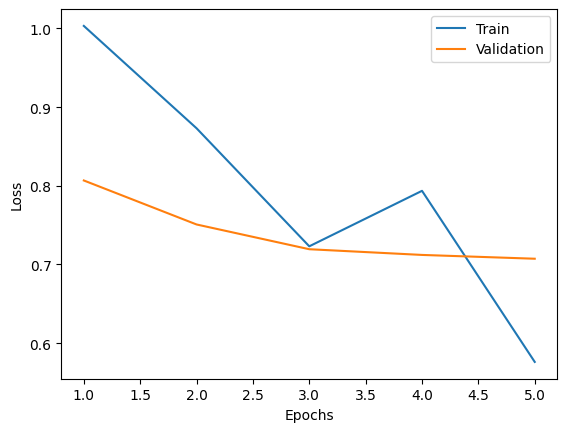

1224


In [2]:
from architecture import BaselineConvNet
loss_fn = nn.CrossEntropyLoss()
n_epochs = 5
device = "cuda" if torch.cuda.is_available() else "cpu"

baseline_model= BaselineConvNet(n_classes=n_classes).to(device)
baseline_optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)
baseline_train_loss, baseline_eval_metrics = train(
    trainloader,
    testloader,
    baseline_model,
    baseline_optimizer,
    loss_fn,
    n_epochs=n_epochs,
)

plot_training_dyn(baseline_train_loss, baseline_eval_metrics)

print(backbone_num_params := baseline_model.backbone_num_params())


## standard bottleneck model

Epoch 1 --- Train loss: 0.683791 -- Val loss 0.837235 -- Val acc.: 63.3 
Epoch 2 --- Train loss: 0.773720 -- Val loss 0.847280 -- Val acc.: 62.6 
Epoch 3 --- Train loss: 0.845156 -- Val loss 0.779046 -- Val acc.: 65.5 
Epoch 4 --- Train loss: 0.746854 -- Val loss 0.792428 -- Val acc.: 66.0 
Epoch 5 --- Train loss: 0.639114 -- Val loss 0.753847 -- Val acc.: 67.4 
Done


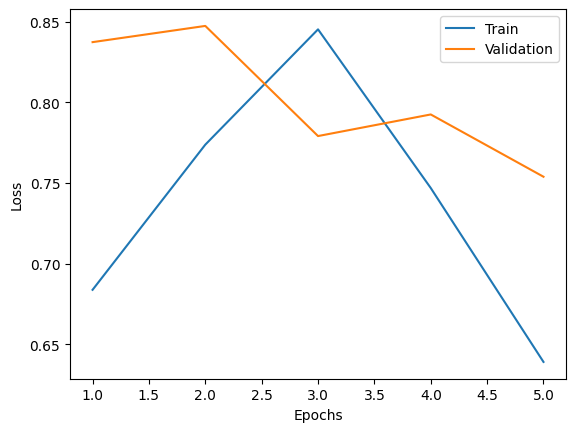

864


In [3]:
from architecture import StandardConvNetBN

loss_fn = nn.CrossEntropyLoss()
n_epochs = 5
device = "cuda" if torch.cuda.is_available() else "cpu"


standard_model = StandardConvNetBN(n_classes=n_classes).to(device)

standard_optimizer = torch.optim.Adam(standard_model.parameters(), lr=1e-3)
standard_train_loss, standard_eval_metrics = train(
    trainloader,
    testloader,
    standard_model,
    standard_optimizer,
    loss_fn,
    n_epochs=n_epochs,
)

plot_training_dyn(standard_train_loss, standard_eval_metrics)

print(backbone_num_params := standard_model.backbone_num_params())



## Evaluate the standard bottleneck model

In [4]:
from train import model_evaluation,plot_cfm

standard_results = model_evaluation(
    standard_model,
    testloader,
    num_classes=len(class_names),
    topk=3,
)
#
print(f"Standard Top-1 accuracy: {standard_results['top1_accuracy']:.4f}")
print(f"Standard Top-3 accuracy: {standard_results['topk_accuracy']:.4f}")
print_per_class_metrics(standard_results, class_names, model_name="Standard")


Standard Top-1 accuracy: 0.6740
Standard Top-3 accuracy: 0.9842
Standard per-class metrics:
  car          precision=0.8925 recall=0.9300 f1=0.9109
  bird         precision=0.6680 recall=0.6760 f1=0.6720
  cat          precision=0.5239 recall=0.5160 f1=0.5199
  dog          precision=0.5973 recall=0.5740 f1=0.5854


## Inverted bottleneck model

Epoch 1 --- Train loss: 0.616940 -- Val loss 0.752155 -- Val acc.: 66.8 
Epoch 2 --- Train loss: 0.600720 -- Val loss 0.725286 -- Val acc.: 68.4 
Epoch 3 --- Train loss: 0.655492 -- Val loss 0.727057 -- Val acc.: 69.4 
Epoch 4 --- Train loss: 0.475096 -- Val loss 0.762012 -- Val acc.: 68.8 
Epoch 5 --- Train loss: 0.534515 -- Val loss 0.807327 -- Val acc.: 69.3 
Done


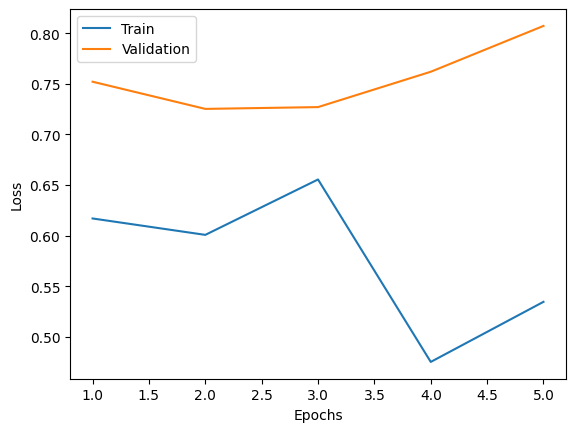

1104


In [5]:
from architecture import InvertedConvNetBN

loss_fn = nn.CrossEntropyLoss()
n_epochs = 5
device = "cuda" if torch.cuda.is_available() else "cpu"

inverted_model = InvertedConvNetBN(n_classes=n_classes).to(device)

inverted_optimizer = torch.optim.Adam(inverted_model.parameters(), lr=1e-3)
inverted_train_loss, inverted_eval_metrics = train(
    trainloader,
    testloader,
    inverted_model,
    inverted_optimizer,
    loss_fn,
    n_epochs=n_epochs,
)

plot_training_dyn(inverted_train_loss, inverted_eval_metrics)

print(backbone_num_params := inverted_model.backbone_num_params())



## Evaluate the inverted bottleneck model

In [6]:
inverted_results = model_evaluation(
    inverted_model,
    testloader,
    num_classes=len(class_names),
    topk=3,
)

print(f"Inverted Top-1 accuracy: {inverted_results['top1_accuracy']:.4f}")
print(f"Inverted Top-3 accuracy: {inverted_results['topk_accuracy']:.4f}")
print_per_class_metrics(inverted_results, class_names, model_name="Inverted")



Inverted Top-1 accuracy: 0.6933
Inverted Top-3 accuracy: 0.9802
Inverted per-class metrics:
  car          precision=0.9111 recall=0.9220 f1=0.9165
  bird         precision=0.6733 recall=0.7110 f1=0.6916
  cat          precision=0.5439 recall=0.5950 f1=0.5683
  dog          precision=0.6504 recall=0.5450 f1=0.5930


Interpretation note:
The classification metrics are useful for checking that the models learn the task, but the report focuses on the internal block-2 feature maps. They should therefore be treated as supporting diagnostics, not as direct evidence of superposition.


## side-by-side comparison

In [7]:
#standard model metrics 
print(f"Standard Top-1 accuracy: {standard_results['top1_accuracy']:.4f}")
print(f"Standard Top-3 accuracy: {standard_results['topk_accuracy']:.4f}")
print_per_class_metrics(standard_results, class_names, model_name="Standard")
print(f"top3-top1 accuracy gap: {standard_results['topk_accuracy'] - standard_results['top1_accuracy']:.4f}")

print("\n") 

#inverted model metrics 

print(f"Inverted Top-1 accuracy: {inverted_results['top1_accuracy']:.4f}")
print(f"Inverted Top-3 accuracy: {inverted_results['topk_accuracy']:.4f}")
print_per_class_metrics(inverted_results, class_names, model_name="Inverted")
print(f"top3-top1 accuracy gap: {inverted_results['topk_accuracy'] - inverted_results['top1_accuracy']:.4f}")



Standard Top-1 accuracy: 0.6740
Standard Top-3 accuracy: 0.9842
Standard per-class metrics:
  car          precision=0.8925 recall=0.9300 f1=0.9109
  bird         precision=0.6680 recall=0.6760 f1=0.6720
  cat          precision=0.5239 recall=0.5160 f1=0.5199
  dog          precision=0.5973 recall=0.5740 f1=0.5854
top3-top1 accuracy gap: 0.3102


Inverted Top-1 accuracy: 0.6933
Inverted Top-3 accuracy: 0.9802
Inverted per-class metrics:
  car          precision=0.9111 recall=0.9220 f1=0.9165
  bird         precision=0.6733 recall=0.7110 f1=0.6916
  cat          precision=0.5439 recall=0.5950 f1=0.5683
  dog          precision=0.6504 recall=0.5450 f1=0.5930
top3-top1 accuracy gap: 0.2870


### Recuperer les feature maps du baseline, du bottleneck standard et inverted

In [8]:
# Collecting block2 feature maps because the representation measures use these activations
from utils import collect_block2_feature_maps

# Collect les outputs du block2 , limite a 200 batches c'est lourd
feats_base= collect_block2_feature_maps(baseline_model, testloader, device, max_batches=200)
feats_std = collect_block2_feature_maps(standard_model, testloader, device, max_batches=200)
feats_inv = collect_block2_feature_maps(inverted_model, testloader, device, max_batches=200)

print(f"Collected baseline batches: {len(feats_base)}")
print(f"Collected standard batches: {len(feats_std)}")
print(f"Collected inverted batches: {len(feats_inv)}")
print(f"Shape of baseline features: {feats_base[0].shape}")
print(f"Shape of standard features: {feats_std[0].shape}")
print(f"Shape of inverted features: {feats_inv[0].shape}")


Collected baseline batches: 63
Collected standard batches: 63
Collected inverted batches: 63
Shape of baseline features: torch.Size([64, 8, 6, 6])
Shape of standard features: torch.Size([64, 8, 14, 14])
Shape of inverted features: torch.Size([64, 8, 14, 14])


Calcul du cosine similarity entre canaux (matrice CxC)

torch.Size([8, 8])
torch.Size([8, 8])
torch.Size([8, 8])
Baseline stats: {'C': 8, 'mean_offdiag': 0.41980844736099243, 'mean_abs_offdiag': 0.41980844736099243, 'max_abs_offdiag': 0.7063460946083069, 'frac_abs_gt_0.5': 0.25}
Standard stats: {'C': 8, 'mean_offdiag': -0.02943972311913967, 'mean_abs_offdiag': 0.3246906101703644, 'max_abs_offdiag': 0.9198945164680481, 'frac_abs_gt_0.5': 0.25}
Inverted stats: {'C': 8, 'mean_offdiag': -0.046604666858911514, 'mean_abs_offdiag': 0.14500360190868378, 'max_abs_offdiag': 0.4398104250431061, 'frac_abs_gt_0.5': 0.0}


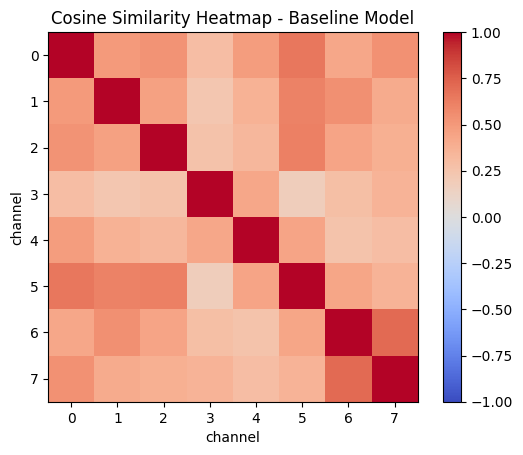

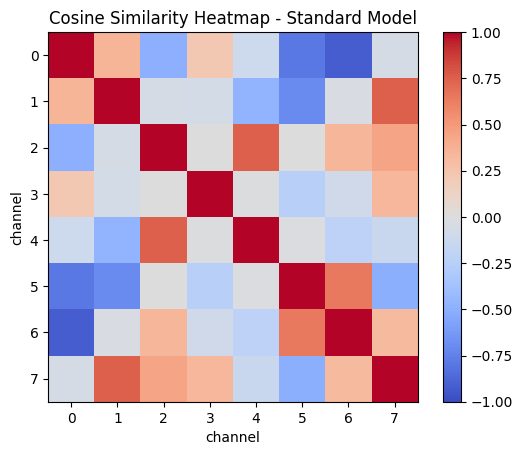

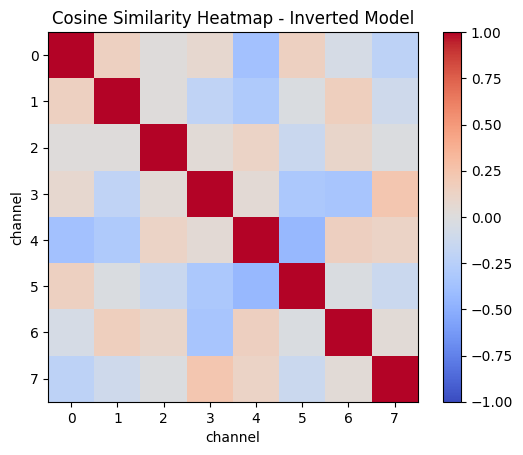

In [9]:
# Computing cosine similarity matrices to see which architecture has the most overlapping channel representations
from utils import cosine_similarity_channels_from_feats, plot_cosine_heatmap

if "feats_base" not in globals() or "feats_std" not in globals() or "feats_inv" not in globals():
    raise RuntimeError("Run the previous feature-map collection cell first.")

similarity_matrix_bsl, stats_bsl = cosine_similarity_channels_from_feats(feats_base)
similarity_matrix_std, stats_std = cosine_similarity_channels_from_feats(feats_std)
similarity_matrix_inv, stats_inv = cosine_similarity_channels_from_feats(feats_inv)

print(similarity_matrix_bsl.shape)  # [C, C]
print(similarity_matrix_std.shape)  # [C, C]
print(similarity_matrix_inv.shape)  # [C, C]

print("Baseline stats:", stats_bsl)
print("Standard stats:", stats_std)
print("Inverted stats:", stats_inv)

plot_cosine_heatmap(similarity_matrix_bsl, title="Cosine Similarity Heatmap - Baseline Model")
plot_cosine_heatmap(similarity_matrix_std, title="Cosine Similarity Heatmap - Standard Model")
plot_cosine_heatmap(similarity_matrix_inv, title="Cosine Similarity Heatmap - Inverted Model")

#* mean_offdiag : moy des valeurs hors diagonale
#* mean_abs_offdiag : moy des valeurs absolues hors diagonale
#* max_abs_offdiag : max des valeurs absolues hors diagonale
#* frac_abs_gt_0_5 : fraction de valeurs absolues hors diagonale > 0.5

Cosine similarity note:
Here C=8, so each heatmap is an 8x8 matrix comparing the measured block-2 channels. The diagonal corresponds to each channel compared with itself. Off-diagonal values close to 0 indicate weak directional alignment, while large absolute values indicate stronger channel overlap or anti-correlation. This is used as an indirect proxy for representational overlap.


Effective Rank Measure

In [10]:
# Computing effective rank to see which architecture uses the most independent representation directions
from utils import effective_rank_channels_from_feats

if "feats_base" not in globals() or "feats_std" not in globals() or "feats_inv" not in globals():
    raise RuntimeError("Run the feature-map collection cell first.")

erank_bsl, erank_stats_bsl = effective_rank_channels_from_feats(feats_base)
erank_std, erank_stats_std = effective_rank_channels_from_feats(feats_std)
erank_inv, erank_stats_inv = effective_rank_channels_from_feats(feats_inv)

print("Baseline effective rank:", erank_stats_bsl)
print("Standard effective rank:", erank_stats_std)
print("Inverted effective rank:", erank_stats_inv)

Baseline effective rank: {'C': 8, 'effective_rank': 7.040637016296387, 'normalized_effective_rank': 0.8800796270370483, 'singular_values': [878.7997436523438, 446.3753356933594, 377.9516906738281, 331.3480529785156, 269.25909423828125, 246.2063446044922, 221.45814514160156, 202.54598999023438]}
Standard effective rank: {'C': 8, 'effective_rank': 4.1000142097473145, 'normalized_effective_rank': 0.5125017762184143, 'singular_values': [1498.322998046875, 1336.3831787109375, 1240.208984375, 1048.746337890625, 37.258426666259766, 0.0010085947578772902, 0.0006601494387723505, 7.898559852037579e-05]}
Inverted effective rank: {'C': 8, 'effective_rank': 7.731931209564209, 'normalized_effective_rank': 0.9664914011955261, 'singular_values': [1370.4068603515625, 1186.881103515625, 1095.801025390625, 978.3458862304688, 898.267578125, 857.3663330078125, 658.1572265625, 580.7579345703125]}


Effective rank note:
Here C=8, so effective rank is between 1 and 8. A lower value means that the representation is concentrated in fewer dominant directions, while a higher value means that the channels use more independent directions overall.
